# 04 — MLP de classificação: baseline

Problema multiclasse (`Low/Moderate/High`): 3 logits + `CrossEntropyLoss`, rótulos inteiros. F1-macro é a métrica principal. O teste permanece reservado.

In [1]:
import json, sys
sys.path.append('..')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler
from src.config import (CLASSIFICATION_DATASET, CLASSIFICATION_TARGET, SEED, RISK_ENCODING,
                        FIGURES_DIR, TABLES_DIR, REPORTS_DIR)
from src.models import MLP
from src.split import carregar_split
from src.train import set_seed, criar_loader, treinar_modelo
torch.set_num_threads(2)
print('PyTorch:', torch.__version__, '| threads:', torch.get_num_threads())

PyTorch: 2.15.0+cpu | threads: 2


## Dados e padronização

In [2]:
df = pd.read_csv(CLASSIFICATION_DATASET)
FEATURES = [c for c in df.columns if c != CLASSIFICATION_TARGET]
split = carregar_split('classificacao')
X = df[FEATURES].to_numpy(dtype=np.float32)
y = df[CLASSIFICATION_TARGET].map(RISK_ENCODING).to_numpy(dtype=np.int64)
scaler = StandardScaler().fit(X[split.train])
Xs = scaler.transform(X).astype(np.float32)
print(len(FEATURES), 'features |', len(split.train), 'treino |', len(split.val), 'validacao')

85 features | 32000 treino | 8000 validacao


## Baseline e treino

In [3]:
gen = set_seed(SEED)
dl_tr = criar_loader(Xs[split.train], y[split.train], 128, True, 'classificacao', gen)
dl_val = criar_loader(Xs[split.val], y[split.val], 256, False, 'classificacao')
modelo = MLP(len(FEATURES), 3, hidden=(32, 32), activation='ReLU')
res = treinar_modelo(modelo, dl_tr, dl_val, torch.nn.CrossEntropyLoss(),
                     torch.optim.Adam(modelo.parameters(), lr=1e-3),
                     n_epocas=200, paciencia=20,
                     metric_fn=lambda yt, ys: f1_score(yt, ys.argmax(1), average='macro', zero_division=0))
print('parada:', res.stop_epoch, '| melhor:', res.best_epoch, '| tempo:', round(res.duration_s, 1), 's')
print('F1 macro treino=%.4f validacao=%.4f' % (res.metricas_finais['treino'], res.metricas_finais['validacao']))

parada: 23 | melhor: 3 | tempo: 70.4 s
F1 macro treino=0.8054 validacao=0.7898


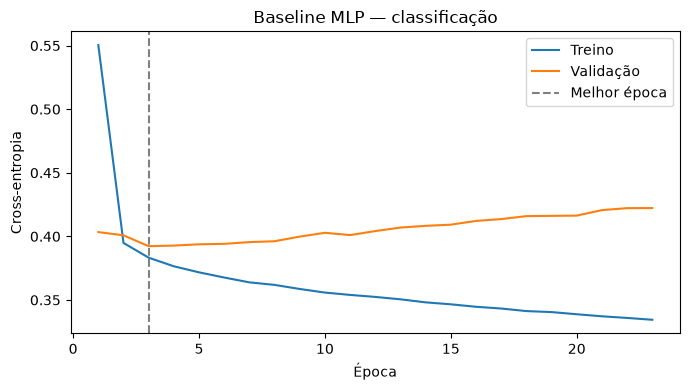

In [4]:
ep = np.arange(1, len(res.history['treino_loss']) + 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ep, res.history['treino_loss'], label='Treino')
ax.plot(ep, res.history['val_loss'], label='Validação')
ax.axvline(res.best_epoch, color='grey', linestyle='--', label='Melhor época')
ax.set(xlabel='Época', ylabel='Cross-entropia', title='Baseline MLP — classificação')
ax.legend(); fig.tight_layout()
fig.savefig(FIGURES_DIR / '04_mlp_classificacao_perda.png', dpi=150)
plt.show()

In [5]:
MODELS_DIR = REPORTS_DIR / 'models'
pd.DataFrame({'epoca': ep, 'loss_treino': res.history['treino_loss'],
              'loss_validacao': res.history['val_loss']}).to_csv(
    TABLES_DIR / '04_mlp_classificacao_historico.csv', index=False)
meta = {'problema': 'classificacao', 'features': FEATURES,
        'configuracao': modelo.configuracao(), 'semente': SEED,
        'batch_size': 128, 'learning_rate': 1e-3, 'perda': 'CrossEntropyLoss',
        'f1_treino': res.metricas_finais['treino'],
        'f1_validacao': res.metricas_finais['validacao'],
        'epoca_melhor': res.best_epoch, 'tempo_s': res.duration_s}
(MODELS_DIR / '04_baseline_classificacao.json').write_text(
    json.dumps(meta, indent=2, ensure_ascii=False), encoding='utf-8')
print('artefatos salvos')

artefatos salvos
